In [14]:
from collections import deque
import networkx as nx
import matplotlib.pyplot as plt

In [15]:
grafo = {
    "Repositorio-Local": ["Servidor-Git"],
    "Servidor-Git": ["Orquestador-CI"],
    "Orquestador-CI": ["Analizador-Calidad", "Compilador"],
    "Analizador-Calidad": ["Gestor-Pipeline", "Servicio-Pruebas"],
    "Compilador": ["Registro-Contenedores", "Gestor-Pipeline"],
    "Gestor-Pipeline": ["Entorno-Producción"],
    "Registro-Contenedores": ["Entorno-Producción"],
    "Entorno-Producción": ["Repositorio-Backups"]

}

inicio = "Repositorio-Local"
meta = "Entorno-Producción"


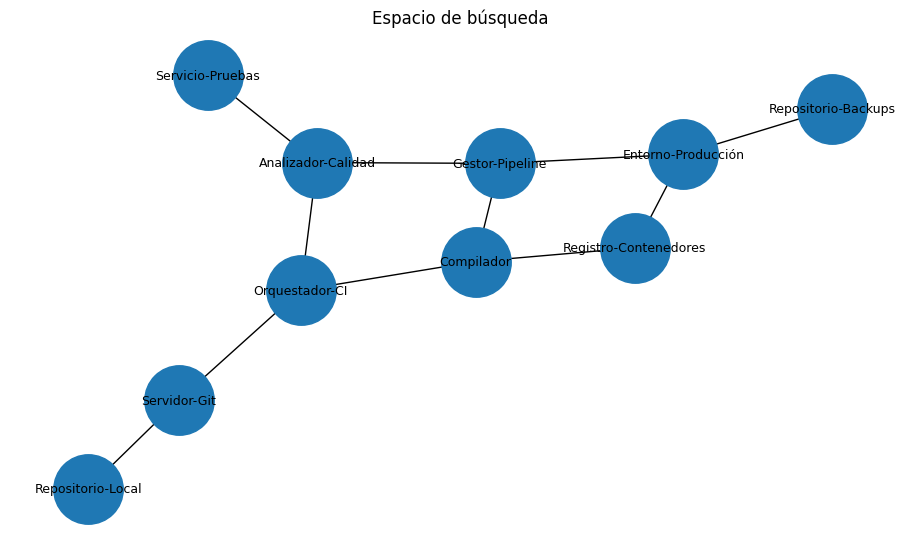

In [16]:
G = nx.Graph()

for estado, vecinos in grafo.items():
    G.add_node(estado)
    for vecino in vecinos:
        G.add_edge(estado, vecino)

plt.figure(figsize=(9,5))
nx.draw(G, with_labels=True, node_size=2500, font_size=9)
plt.title("Espacio de búsqueda")
plt.show()


## Función BFS





In [17]:
def bfs(grafo, inicio, meta, mostrar=True):
    cola = deque([(inicio, [inicio])])
    visitados = set()
    orden = []

    while cola:
        if mostrar:
            print("Cola:", [n for n, _ in cola])

        nodo, camino = cola.popleft()

        if nodo in visitados:
            continue

        visitados.add(nodo)
        orden.append(nodo)

        if mostrar:
            print("Visitando:", nodo, "| Total visitados:", len(visitados))

        if nodo == meta:
            return orden, camino

        for vecino in grafo.get(nodo, []):
            if vecino not in visitados:
                cola.append((vecino, camino + [vecino]))

    return orden, None
orden_bfs, camino_bfs = bfs(grafo, inicio, meta)
print("\nOrden de visita final:", orden_bfs)
print("Camino más corto encontrado:", camino_bfs)


Cola: ['Repositorio-Local']
Visitando: Repositorio-Local
Cola: ['Servidor-Git']
Visitando: Servidor-Git
Cola: ['Orquestador-CI']
Visitando: Orquestador-CI
Cola: ['Analizador-Calidad', 'Compilador']
Visitando: Analizador-Calidad
Cola: ['Compilador', 'Gestor-Pipeline', 'Servicio-Pruebas']
Visitando: Compilador
Cola: ['Gestor-Pipeline', 'Servicio-Pruebas', 'Registro-Contenedores', 'Gestor-Pipeline']
Visitando: Gestor-Pipeline
Cola: ['Servicio-Pruebas', 'Registro-Contenedores', 'Gestor-Pipeline', 'Entorno-Producción']
Visitando: Servicio-Pruebas
Cola: ['Registro-Contenedores', 'Gestor-Pipeline', 'Entorno-Producción']
Visitando: Registro-Contenedores
Cola: ['Gestor-Pipeline', 'Entorno-Producción', 'Entorno-Producción']
Cola: ['Entorno-Producción', 'Entorno-Producción']
Visitando: Entorno-Producción

Orden de visita final: ['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Analizador-Calidad', 'Compilador', 'Gestor-Pipeline', 'Servicio-Pruebas', 'Registro-Contenedores', 'Entorno-Produc

## Función DFS





In [23]:
def dfs(grafo, inicio, meta, mostrar=True):
    pila = [(inicio, [inicio])]
    visitados = set()
    orden = []

    while pila:
        if mostrar:
            print("Pila:", [n for n, _ in pila])

        nodo, camino = pila.pop()

        if nodo in visitados:
            continue

        visitados.add(nodo)
        orden.append(nodo)

        if mostrar:
            print("Visitando:", nodo, "| Total visitados:", len(visitados))

        if nodo == meta:
            return orden, camino

        for vecino in reversed(grafo.get(nodo, [])):
            if vecino not in visitados:
                pila.append((vecino, camino + [vecino]))

    return orden, None

orden_dfs, camino_dfs = dfs(grafo, inicio, meta)
print("\nOrden DFS:", orden_dfs)
print("Camino DFS:", camino_dfs)

Pila: ['Repositorio-Local']
Visitando: Repositorio-Local | Total visitados: 1
Pila: ['Servidor-Git']
Visitando: Servidor-Git | Total visitados: 2
Pila: ['Orquestador-CI']
Visitando: Orquestador-CI | Total visitados: 3
Pila: ['Compilador', 'Analizador-Calidad']
Visitando: Analizador-Calidad | Total visitados: 4
Pila: ['Compilador', 'Servicio-Pruebas', 'Gestor-Pipeline']
Visitando: Gestor-Pipeline | Total visitados: 5
Pila: ['Compilador', 'Servicio-Pruebas', 'Entorno-Producción']
Visitando: Entorno-Producción | Total visitados: 6

Orden DFS: ['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Analizador-Calidad', 'Gestor-Pipeline', 'Entorno-Producción']
Camino DFS: ['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Analizador-Calidad', 'Gestor-Pipeline', 'Entorno-Producción']


## Parte D. Comparación inicial

* **Orden de visita de BFS:**  
  `['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Analizador-Calidad', 'Compilador', 'Gestor-Pipeline', 'Servicio-Pruebas', 'Registro-Contenedores', 'Entorno-Producción']`

* **Camino encontrado por BFS:**  
  `['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Analizador-Calidad', 'Gestor-Pipeline', 'Entorno-Producción']`

* **Orden de visita de DFS:**  
  `['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Analizador-Calidad', 'Gestor-Pipeline', 'Entorno-Producción']`

* **Camino encontrado por DFS:**  
  `['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Analizador-Calidad', 'Gestor-Pipeline', 'Entorno-Producción']`

* **Número de estados visitados por cada algoritmo:**
  * **BFS:** 9 estados visitados.
  * **DFS:** 6 estados visitados.

* **Número de pasos (aristas/transiciones) del camino encontrado por cada algoritmo:**
  * **BFS:** 5 pasos (longitud del camino: 6 nodos).
  * **DFS:** 5 pasos (longitud del camino: 6 nodos).

## Parte E. Incidente en el sistema

Durante la operación ocurre una falla en `Analizador-Calidad`. El elemento continúa formando parte del sistema, pero queda fuera de servicio y no puede establecer comunicación con los demás elementos.

Modificamos el grafo bajo las siguientes condiciones:
* `Analizador-Calidad` continúa apareciendo como nodo.
* `Analizador-Calidad` queda sin conexiones salientes.
* Se eliminan todas las referencias hacia `Analizador-Calidad` desde los demás estados.

In [19]:
import copy

grafo_falla = copy.deepcopy(grafo)

grafo_falla["Analizador-Calidad"] = []

for estado in grafo_falla:
    grafo_falla[estado] = [vecino for vecino in grafo_falla[estado] if vecino != "Analizador-Calidad"]

print("Grafo modificado (con falla):")
for nodo, vecinos in grafo_falla.items():
    print(f"{nodo}: {vecinos}")

Grafo modificado (con falla):
Repositorio-Local: ['Servidor-Git']
Servidor-Git: ['Orquestador-CI']
Orquestador-CI: ['Compilador']
Analizador-Calidad: []
Compilador: ['Registro-Contenedores', 'Gestor-Pipeline']
Gestor-Pipeline: ['Entorno-Producción']
Registro-Contenedores: ['Entorno-Producción']
Entorno-Producción: ['Repositorio-Backups']


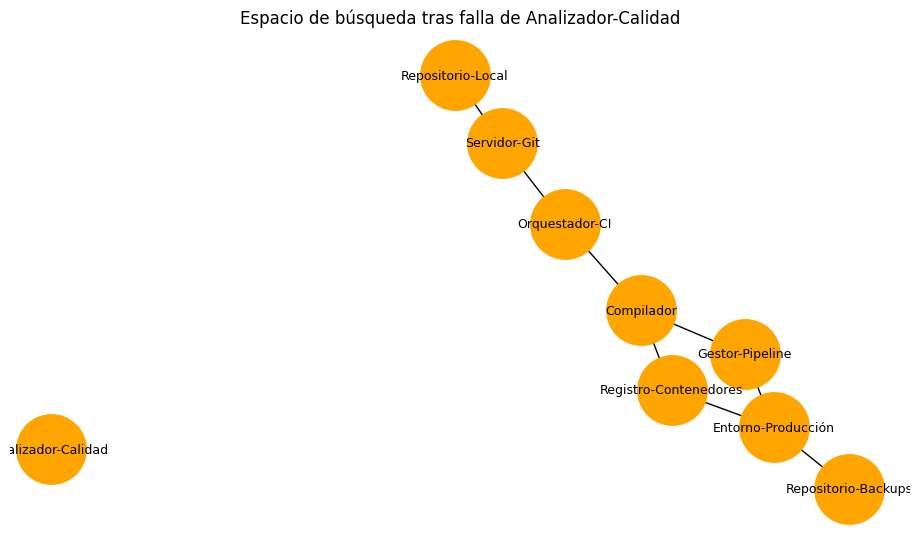

In [20]:
G_falla = nx.Graph()

for estado, vecinos in grafo_falla.items():
    G_falla.add_node(estado)
    for vecino in vecinos:
        G_falla.add_edge(estado, vecino)

plt.figure(figsize=(9,5))
nx.draw(G_falla, with_labels=True, node_size=2500, font_size=9, node_color='orange')
plt.title("Espacio de búsqueda tras falla de Analizador-Calidad")
plt.show()

In [21]:
print("=== BFS tras la falla ===")
orden_bfs_falla, camino_bfs_falla = bfs(grafo_falla, inicio, meta, mostrar=False)
print("Orden de visita:", orden_bfs_falla)
print("Camino encontrado:", camino_bfs_falla)
print("Estados visitados:", len(orden_bfs_falla))
print("Pasos:", len(camino_bfs_falla) - 1 if camino_bfs_falla else "N/A")

print("\n=== DFS tras la falla ===")
orden_dfs_falla, camino_dfs_falla = dfs(grafo_falla, inicio, meta, mostrar=False)
print("Orden de visita:", orden_dfs_falla)
print("Camino encontrado:", camino_dfs_falla)
print("Estados visitados:", len(orden_dfs_falla))
print("Pasos:", len(camino_dfs_falla) - 1 if camino_dfs_falla else "N/A")

=== BFS tras la falla ===
Orden de visita: ['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Compilador', 'Registro-Contenedores', 'Gestor-Pipeline', 'Entorno-Producción']
Camino encontrado: ['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Compilador', 'Registro-Contenedores', 'Entorno-Producción']
Estados visitados: 7
Pasos: 5

=== DFS tras la falla ===
Orden de visita: ['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Compilador', 'Registro-Contenedores', 'Entorno-Producción']
Camino encontrado: ['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Compilador', 'Registro-Contenedores', 'Entorno-Producción']
Estados visitados: 6
Pasos: 5


### ¿Existe todavía un camino entre Repositorio-Local y Entorno-Producción?

**Sí, todavía existe un camino.** Al quedar aislado el `Analizador-Calidad`, ambos algoritmos fueron capaces de encontrar una ruta alternativa a través de la otra bifurcación (`Compilador`), logrando llegar de forma exitosa a la meta.

* **Camino BFS encontrado:** `['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Compilador', 'Gestor-Pipeline', 'Entorno-Producción']` (o usando `Registro-Contenedores` en lugar de `Gestor-Pipeline` según el orden de expansión).
* **Camino DFS encontrado:** `['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Compilador', 'Gestor-Pipeline', 'Entorno-Producción']`

## Parte F. Cambio de objetivo

Sin restaurar `Analizador-Calidad`, cambiamos el estado meta a `Servicio-Pruebas`. Ejecutamos BFS y DFS para verificar que el programa es capaz de indicar adecuadamente la inexistencia de un camino sin quedarse atrapado en ejecuciones infinitas.

In [22]:
nueva_meta = "Servicio-Pruebas"

print("=== BFS buscando 'Servicio-Pruebas' (Con Falla) ===")
orden_bfs_p, camino_bfs_p = bfs(grafo_falla, inicio, nueva_meta, mostrar=False)
print("Orden de visita:", orden_bfs_p)
print("Camino encontrado:", "No existe solución" if camino_bfs_p is None else camino_bfs_p)

print("\n=== DFS buscando 'Servicio-Pruebas' (Con Falla) ===")
orden_dfs_p, camino_dfs_p = dfs(grafo_falla, inicio, nueva_meta, mostrar=False)
print("Orden de visita:", orden_dfs_p)
print("Camino encontrado:", "No existe solución" if camino_dfs_p is None else camino_dfs_p)

=== BFS buscando 'Servicio-Pruebas' (Con Falla) ===
Orden de visita: ['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Compilador', 'Registro-Contenedores', 'Gestor-Pipeline', 'Entorno-Producción', 'Repositorio-Backups']
Camino encontrado: No existe solución

=== DFS buscando 'Servicio-Pruebas' (Con Falla) ===
Orden de visita: ['Repositorio-Local', 'Servidor-Git', 'Orquestador-CI', 'Compilador', 'Registro-Contenedores', 'Entorno-Producción', 'Repositorio-Backups', 'Gestor-Pipeline']
Camino encontrado: No existe solución


## Parte G. Análisis e Interpretación

### 1. ¿Por qué BFS y DFS pueden visitar los mismos estados en diferente orden?
Porque implementan estructuras de datos distintas para gestionar el orden de expansión de los nodos. BFS utiliza una cola (FIFO), lo que obliga a explorar el grafo de forma radial o por niveles completos antes de avanzar al siguiente nivel de profundidad. Por su parte, DFS implementa una pila (LIFO), lo que hace que priorice ir hasta el nodo más profundo de una rama antes de realizar el retroceso (backtracking) para explorar otras alternativas.

### 2. ¿Cuál de los dos algoritmos encontró inicialmente el camino con menor número de pasos? Explica.
Ambos algoritmos encontraron inicialmente un camino con el mismo número de pasos (5 pasos / 6 nodos). Esto sucede debido a que, por la topología del grafo y la declaración ordenada de las conexiones vecinas, la primera rama profunda explorada por DFS coincide directamente con una de las rutas más eficientes hacia la meta, eliminando la diferencia habitual de rendimiento en longitud que suele favorecer a BFS.

### 3. ¿Qué efecto tuvo la falla de Analizador-Calidad sobre el espacio de búsqueda?
La falla redujo las trayectorias viables eliminando aristas activas. Esto alteró el flujo del sistema, obligando a los algoritmos a redirigir la búsqueda exclusivamente a través de la rama alterna controlada por el nodo 'Compilador', además de provocar que el nodo 'Servicio-Pruebas' quede completamente inaccesible.

### 4. ¿Por qué Analizador-Calidad debe seguir apareciendo en el grafo aunque no tenga conexiones?
Porque representa un componente real dentro de la arquitectura física del sistema. Aunque se encuentre inoperativo o aislado, mantenerlo en el grafo es fundamental para reflejar el estado real de la infraestructura, permitir auditorías visuales precisas y planificar tareas de diagnóstico o mantenimiento sobre dicho componente.

### 5. Cuando la meta cambió a Servicio-Pruebas, ¿cómo determinó el programa que no existía solución?
El programa determina la inexistencia de solución de manera segura mediante el control de la lista de nodos visitados y el vaciado de la frontera. Como el nodo meta 'Servicio-Pruebas' no tiene aristas que apunten a él debido a la falla de 'Analizador-Calidad', los algoritmos expanden y marcan como visitados todos los nodos alcanzables posibles. Al agotarse los elementos dentro de la cola (BFS) o de la pila (DFS) sin encontrar el objetivo, el bucle finaliza de forma segura retornando un valor nulo (None).

### 6. En un pipeline real, ¿qué otros criterios además del número de pasos deberían considerarse para seleccionar un flujo de despliegue?
* **Tiempos de ejecución:** El costo temporal de cada tarea (ej. compilación vs pruebas unitarias).
* **Consumo de recursos:** Uso de CPU, memoria o costos asociados a servidores temporales.
* **Criticidad de seguridad:** Nivel de análisis requerido (pruebas estáticas de seguridad, análisis de vulnerabilidades).
* **Estado de salud de los nodos:** Monitoreo en tiempo real de la disponibilidad de cada servidor o servicio de la infraestructura.

### 7. ¿Qué utilidad puede tener modelar un pipeline como grafo cuando ocurre una falla en una de sus etapas?
Permite que el sistema tenga resiliencia y tolerancia a fallos. Al estar modelado como un grafo estructurado, un orquestador automatizado puede recalcular dinámicamente y en tiempo real una ruta de despliegue alternativa evitando la interrupción total del flujo operativo.

---
